<a href="https://colab.research.google.com/github/piaoruilin/hallucination-medical-vlm/blob/main/stage1_complete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 1: trivial baselines for hallucination detection
Scores simple detectors on your Qwen-injected data (word-level labels), so you know the floor a real detector must beat.

**Part A (cells 2-6) needs no GPU.** Part B (cells 7-9) loads Qwen as an LLM judge and needs a GPU.
All scores are for the *hallucinated* class: precision, recall, F1 (not plain accuracy, since most words are label 0).

In [1]:
!pip install -q "bitsandbytes>=0.46.1" accelerate transformers tqdm
# If this installs something new, do Runtime > Restart session once, then skip this cell.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.2 MB/s eta 0:00:00


## Part A: load data and score the no-model baselines

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import re, json, random, numpy as np, pandas as pd

JSONL_PATH = "/content/drive/MyDrive/halluc_injected.jsonl"
SAVE_DIR   = "/content/drive/MyDrive/halluc_baselines"
BAD_ROWS   = []     # put the `row` ids of any pairs you judged bad after reading your sample

d = pd.read_json(JSONL_PATH, lines=True)
d = d[~d["row"].isin(BAD_ROWS)].reset_index(drop=True)

assert all(len(t) == len(l) for t, l in zip(d["tokens"], d["labels"])), "tokens and labels differ in length"
n_words = int(d["tokens"].apply(len).sum())
n_pos = int(d["labels"].apply(sum).sum())
print(len(d), "samples |", n_words, "words |", n_pos, "hallucinated words (%.1f%%)" % (100 * n_pos / n_words))
print(d["hallucinated"].value_counts().to_dict())
print(d["type"].value_counts().to_dict())

154 samples | 2086 words | 196 hallucinated words (9.4%)
{1: 77, 0: 77}
{'invented_finding': 56, 'wrong_side': 36, 'wrong_attribute': 32, 'wrong_organ': 30}


In [4]:
def norm_word(w):
    return re.sub(r"[^a-z0-9]", "", str(w).lower())

def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return p, r, f

def evaluate(df, col):
    # word level: all words from all samples pooled
    tp = fp = fn = 0
    for labels, pred in zip(df["labels"], df[col]):
        for l, p in zip(labels, pred):
            tp += int(l == 1 and p == 1)
            fp += int(l == 0 and p == 1)
            fn += int(l == 1 and p == 0)
    wP, wR, wF = prf(tp, fp, fn)
    # sample level: a sample counts as "flagged" if any word is flagged
    y = df["hallucinated"].values
    yhat = df[col].apply(lambda p: int(any(p))).values
    stp = int(((y == 1) & (yhat == 1)).sum())
    sfp = int(((y == 0) & (yhat == 1)).sum())
    sfn = int(((y == 1) & (yhat == 0)).sum())
    sP, sR, sF = prf(stp, sfp, sfn)
    return {"word_P": wP, "word_R": wR, "word_F1": wF,
            "sample_P": sP, "sample_R": sR, "sample_F1": sF, "sample_acc": float((y == yhat).mean())}

def by_type(df, col):
    rows = []
    for t, g in df[df["hallucinated"] == 1].groupby("type"):
        tp = sum(sum(1 for l, p in zip(L, P) if l == 1 and p == 1) for L, P in zip(g["labels"], g[col]))
        pos = sum(sum(L) for L in g["labels"])
        rows.append({"type": t, "n": len(g),
                     "word_recall": tp / pos if pos else 0.0,
                     "sample_detect_rate": float(g[col].apply(lambda p: int(any(p))).mean())})
    return pd.DataFrame(rows)

results = {}

In [5]:
# 1. flag nothing
d["pred_none"] = d["tokens"].apply(lambda t: [0] * len(t))
results["flag nothing"] = evaluate(d, "pred_none")

# 2. flag every word
d["pred_all"] = d["tokens"].apply(lambda t: [1] * len(t))
results["flag everything"] = evaluate(d, "pred_all")

# 3. flag random words at the true hallucination rate (averaged over 20 seeds)
rate = n_pos / n_words
runs = []
for seed in range(20):
    rng = np.random.default_rng(seed)
    d["_p"] = d["tokens"].apply(lambda t: (rng.random(len(t)) < rate).astype(int).tolist())
    runs.append(evaluate(d, "_p"))
d = d.drop(columns="_p")
results["random (matched rate)"] = pd.DataFrame(runs).mean().to_dict()

pd.DataFrame(results).T.round(3)

,word_P,word_R,word_F1,sample_P,sample_R,sample_F1,sample_acc
flag nothing,0.000,0.000,0.000,0.000,0.000,0.000,0.500
flag everything,0.094,1.000,0.172,0.500,1.000,0.667,0.500
random (matched rate),0.097,0.098,0.098,0.518,0.736,0.608,0.525


**Shortcut check.** A detector trained on injected data can cheat by learning *which kinds of words* Qwen likes to swap (sides, organs, locations).
This baseline flags any word from a small anatomy/laterality list, with no model at all. If it scores well, your data has a shortcut.

In [6]:
LEX = {"left", "right", "upper", "lower", "middle", "anterior", "posterior", "superior", "inferior",
       "bilateral", "lateral", "medial", "lung", "lungs", "liver", "heart", "kidney", "spleen", "brain",
       "lobe", "lobes", "chest", "pleural", "mediastinal", "mediastinum", "small", "large", "mild", "severe"}

d["pred_lexicon"] = d["tokens"].apply(lambda t: [int(norm_word(w) in LEX) for w in t])
results["lexicon shortcut"] = evaluate(d, "pred_lexicon")
pd.DataFrame(results).T.round(3)

,word_P,word_R,word_F1,sample_P,sample_R,sample_F1,sample_acc
flag nothing,0.000,0.000,0.000,0.000,0.000,0.000,0.500
flag everything,0.094,1.000,0.172,0.500,1.000,0.667,0.500
random (matched rate),0.097,0.098,0.098,0.518,0.736,0.608,0.525
lexicon shortcut,0.234,0.398,0.295,0.515,0.896,0.654,0.526


## Part B: LLM judge (needs a GPU)
Qwen reads the question and answer and lists the words it thinks are wrong. It **cannot see the image**, so this is a text-only baseline.
`MODES` can also include `"reference"`, where Qwen is shown the correct answer too. That is an easy "oracle" setting, useful as a check on your labels, not as a real baseline.

In [7]:
import torch
print("GPU available:", torch.cuda.is_available())
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

model_id = "Qwen/Qwen2.5-7B-Instruct"   # use the same Qwen as your injection step
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)
tok = AutoTokenizer.from_pretrained(model_id)
llm = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=bnb, device_map="auto")
llm.eval()

GPU available: True


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(152064, 3584)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear4bit(in_features=3584, out_features=3584, bias=True)
          (k_proj): Linear4bit(in_features=3584, out_features=512, bias=True)
          (v_proj): Linear4bit(in_features=3584, out_features=512, bias=True)
          (o_proj): Linear4bit(in_features=3584, out_features=3584, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear4bit(in_features=3584, out_features=18944, bias=False)
          (up_proj): Linear4bit(in_features=3584, out_features=18944, bias=False)
          (down_proj): Linear4bit(in_features=18944, out_features=3584, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((3584,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((3584,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm

In [8]:
SYSTEM = ("You check answers to medical image questions for hallucinated (incorrect) content. "
          "You cannot see the image. You output only valid JSON.")

def build_prompt(q, a, ref):
    s = "Question: " + str(q) + "\n"
    if ref is not None:
        s += "Reference (correct) answer: " + str(ref) + "\n"
    s += "Answer to check: " + str(a) + "\n\n"
    if ref is None:
        s += ("List the words in the answer that are likely hallucinated: an incorrect organ, side, "
              "location, finding, size or attribute. Copy the words exactly as written.\n")
    else:
        s += ("List the words in the answer that contradict or are not supported by the reference answer. "
              "Copy the words exactly as written.\n")
    s += 'Return only JSON like {"hallucinated_words": ["word1", "word2"]}, or {"hallucinated_words": []} if nothing is wrong.'
    return s

def ask_judge(q, a, ref):
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": build_prompt(q, a, ref)}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors="pt").to(llm.device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=80, do_sample=False)
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)

def parse_json(text):
    m = re.search(r"\{.*\}", text, re.S)
    try:
        return json.loads(m.group(0)) if m else None
    except Exception:
        return None

def flags_from_llm(tokens, words):
    if isinstance(words, str):
        words = [words]
    S = {norm_word(x) for w in words for x in str(w).split()} - {""}
    return [int(norm_word(t) in S) for t in tokens]

MODES = ["no_reference"]      # add "reference" for the oracle check (doubles the run time)

for mode in MODES:
    preds, raws, bad = [], [], 0
    for _, r in tqdm(d.iterrows(), total=len(d)):
        raw = ask_judge(r["question"], r["answer"], r["gt_answer"] if mode == "reference" else None)
        o = parse_json(raw)
        if not isinstance(o, dict):
            bad += 1
            words = []
        else:
            words = o.get("hallucinated_words", [])
        preds.append(flags_from_llm(r["tokens"], words))
        raws.append(raw)
    d["pred_" + mode] = preds
    d["raw_" + mode] = raws
    results["Qwen judge (" + mode + ")"] = evaluate(d, "pred_" + mode)
    print(mode, "unparseable outputs:", bad, "of", len(d))

  0%|          | 0/154 [00:00<?, ?it/s]

no_reference unparseable outputs: 0 of 154


## Results

In [9]:
table = pd.DataFrame(results).T.round(3)
display(table)

for mode in MODES:
    print("\nBy hallucination type, Qwen judge (" + mode + ")")
    display(by_type(d, "pred_" + mode).round(3))

,word_P,word_R,word_F1,sample_P,sample_R,sample_F1,sample_acc
flag nothing,0.000,0.000,0.000,0.000,0.000,0.000,0.500
flag everything,0.094,1.000,0.172,0.500,1.000,0.667,0.500
random (matched rate),0.097,0.098,0.098,0.518,0.736,0.608,0.525
lexicon shortcut,0.234,0.398,0.295,0.515,0.896,0.654,0.526
Qwen judge (no_reference),0.344,0.265,0.300,0.649,0.649,0.649,0.649



By hallucination type, Qwen judge (no_reference)


,type,n,word_recall,sample_detect_rate
0,invented_finding,28,0.186,0.750
1,wrong_attribute,16,0.065,0.312
2,wrong_organ,15,0.483,0.733
3,wrong_side,18,0.652,0.722


In [10]:
# Look at examples: gold hallucinated words vs what the judge flagged
col = "pred_" + MODES[0]
for _, r in d[d["hallucinated"] == 1].sample(10, random_state=0).iterrows():
    gold = [t for t, l in zip(r["tokens"], r["labels"]) if l]
    flagged = [t for t, p in zip(r["tokens"], r[col]) if p]
    print(r["answer"])
    print("   gold:", gold, "| flagged:", flagged)

The chest X-ray showed patchy opacifications with fibrotic shadows in the lower left lung.
   gold: ['lower', 'left'] | flagged: ['lower', 'left']
The previous chest radiography was performed 4 years ago and showed an enlarged cardiothoracic ratio and left pulmonary artery, and a new kidney tumor.
   gold: ['new', 'kidney', 'tumor.'] | flagged: ['kidney']
The images being compared in this caption are from Day 15, which shows significant improvement over Day 22.
   gold: ['Day', '15,', 'which', 'shows', 'significant', 'improvement'] | flagged: ['Day', '15,', 'Day', '22.']
The image shows an enlarged intraoperative visual field in the upper mediastinum.
   gold: ['enlarged'] | flagged: ['intraoperative']
The pleura was thinner in the lower part.
   gold: ['lower'] | flagged: ['thinner']
The chest CT scan shows a primary lesion in the right upper lobe and a small pleural effusion.
   gold: ['pleural'] | flagged: []
The patient's right lung is affected, and there is also a small tumor on t

In [11]:
import os
os.makedirs(SAVE_DIR, exist_ok=True)
table.to_csv(SAVE_DIR + "/stage1_results.csv")
d.to_json(SAVE_DIR + "/stage1_predictions.jsonl", orient="records", lines=True)
print("saved to", SAVE_DIR)

saved to /content/drive/MyDrive/halluc_baselines


# Part C: label quality checks
Run after Part B, in the same session. No GPU needed. Compares Qwen's marked words with a diff against each answer's clean twin.

In [12]:
import difflib

def diff_labels(h_tokens, c_tokens):
    a = [norm_word(t) for t in c_tokens]
    b = [norm_word(t) for t in h_tokens]
    lab = [0] * len(h_tokens)
    for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, a, b, autojunk=False).get_opcodes():
        if tag in ("replace", "insert"):
            for j in range(j1, j2):
                lab[j] = 1
    return lab

def jacc(a, b):
    A = {i for i, l in enumerate(a) if l}
    B = {i for i, l in enumerate(b) if l}
    return len(A & B) / max(1, len(A | B))

twin = d[d["hallucinated"] == 0].set_index("row")["tokens"]
h = d[d["hallucinated"] == 1].copy()
h["diff_labels"] = [diff_labels(t, twin[r]) for t, r in zip(h["tokens"], h["row"])]
h["jacc"] = [jacc(a, b) for a, b in zip(h["labels"], h["diff_labels"])]
print(h["jacc"].describe())
print((h["jacc"] == 1).sum(), "exact agreement |", (h["jacc"] == 0).sum(), "no overlap |", (h["jacc"] < 0.5).sum(), "below 0.5")

count    77.000000
mean      0.620965
std       0.291822
min       0.000000
25%       0.333333
50%       0.500000
75%       1.000000
max       1.000000
Name: jacc, dtype: float64
23 exact agreement | 1 no overlap | 22 below 0.5


In [13]:
# Re-score with the diff labels, then only on pairs where the two labelings agree (Jaccard >= 0.5)
d2 = d.copy()
new = dict(zip(h["row"], h["diff_labels"]))
d2["labels"] = [new[r] if hz == 1 else l for r, hz, l in zip(d2["row"], d2["hallucinated"], d2["labels"])]
d2["jacc"] = d2["row"].map(dict(zip(h["row"], h["jacc"])))
hi = d2[d2["jacc"] >= 0.5]

cols = ["pred_none", "pred_all", "pred_lexicon", "pred_no_reference"]
print("--- diff labels, all rows")
display(pd.DataFrame({c: evaluate(d2, c) for c in cols}).T.round(3))
print("--- diff labels, agreement filter:", len(hi) // 2, "pairs kept")
display(pd.DataFrame({c: evaluate(hi, c) for c in cols}).T.round(3))

--- diff labels, all rows


,word_P,word_R,word_F1,sample_P,sample_R,sample_F1,sample_acc
pred_none,0.000,0.000,0.000,0.000,0.000,0.000,0.500
pred_all,0.127,1.000,0.225,0.500,1.000,0.667,0.500
pred_lexicon,0.207,0.260,0.231,0.515,0.896,0.654,0.526
pred_no_reference,0.305,0.174,0.221,0.649,0.649,0.649,0.649


--- diff labels, agreement filter: 55 pairs kept


,word_P,word_R,word_F1,sample_P,sample_R,sample_F1,sample_acc
pred_none,0.000,0.000,0.000,0.000,0.000,0.000,0.500
pred_all,0.114,1.000,0.205,0.500,1.000,0.667,0.500
pred_lexicon,0.178,0.226,0.199,0.490,0.855,0.623,0.482
pred_no_reference,0.293,0.214,0.247,0.629,0.709,0.667,0.645


In [14]:
# OPTIONAL: bootstrap 95% intervals for word F1 on the filtered set (about a minute)
rows_u = hi["row"].unique()
rng = np.random.default_rng(0)
out = {c: [] for c in ["pred_all", "pred_lexicon", "pred_no_reference"]}
for _ in range(300):
    pick = rng.choice(rows_u, len(rows_u), replace=True)
    b = pd.concat([hi[hi["row"] == r] for r in pick])
    for c in out:
        out[c].append(evaluate(b, c)["word_F1"])
for c in out:
    print(c, "word F1 95% interval:", np.percentile(out[c], [2.5, 97.5]).round(3))

pred_all word F1 95% interval: [0.16  0.244]
pred_lexicon word F1 95% interval: [0.155 0.26 ]
pred_no_reference word F1 95% interval: [0.186 0.308]


# Part D: look at the images
Needs internet. The image archive is about 2.2 GB, so expect a few minutes.

In [15]:
from huggingface_hub import hf_hub_download

# Rebuild the filtered PMC-VQA table exactly as the Qwen run did, then join image paths on `row`
src = pd.read_csv(hf_hub_download("xmcmic/PMC-VQA", "train_2.csv", repo_type="dataset"))
kw = "chest|lung|thora|pulmon|pleur|mediastin"
src = src[src["Question"].astype(str).str.lower().str.contains(kw)].reset_index(drop=True)

d["image"] = d["row"].map(src["Figure_path"])
print("question match rate:", (d["question"] == d["row"].map(src["Question"])).mean(), "(must be 1.0)")

train_2.csv: reconstructing file:   0%|          |  0.00B / 56.7MB            

train_2.csv: downloading bytes:           |  0.00B            

question match rate: 1.0 (must be 1.0)


In [16]:
import zipfile, os, glob

zip_file = hf_hub_download("xmcmic/PMC-VQA", "images_2.zip", repo_type="dataset")
EXTRACT_DIR = "/content/pmcvqa_images"
need = {os.path.basename(p) for p in d["image"].dropna()}

with zipfile.ZipFile(zip_file) as z:
    members = [m for m in z.namelist() if os.path.basename(m) in need]
    z.extractall(EXTRACT_DIR, members=members)
print(len(members), "files extracted for", len(need), "needed")

paths = {os.path.basename(p): p for p in glob.glob(EXTRACT_DIR + "/**/*", recursive=True) if os.path.isfile(p)}

images_2.zip: reconstructing file:   0%|          |  0.00B / 2.21GB            

images_2.zip: downloading bytes:           |  0.00B            

74 files extracted for 74 needed


[37] Q: What was observed in the chest computed tomography on day 21? 
ORIGINAL: Enlargement of the subcarinal and hilar lymph nodes
INJECTED: The subcarinal and hilar lymph nodes were observed to be enlarged, along with the presence of calcifications, on the chest computed tomography performed on day 21.
MARKED:   ['along', 'with', 'the', 'presence', 'of', 'calcifications,']


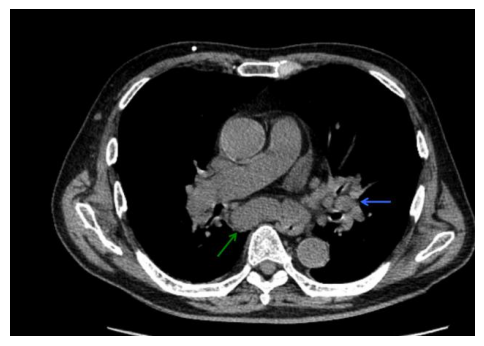

[53] Q: What shape is being identified in the pulmonary image? 
ORIGINAL: Rectangle
INJECTED: The pulmonary image shows a rectangle on the right side.
MARKED:   ['right']


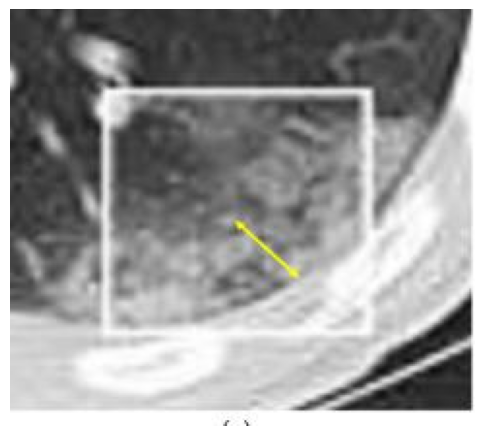

[30] Q: What does the chest CT scan show? 
ORIGINAL: Primary lesion in the right upper lobe and a small pericardial effusion
INJECTED: The chest CT scan shows a primary lesion in the right upper lobe and a small pleural effusion.
MARKED:   ['pleural']


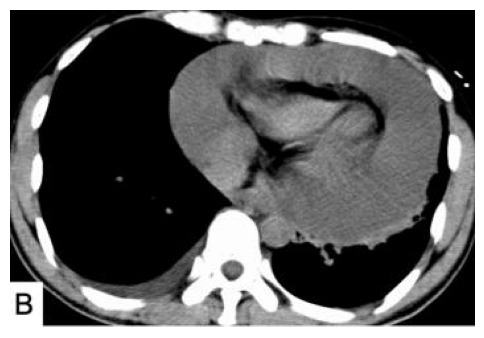

[95] Q:  How long ago was the previous chest radiography performed and what did it show? 
ORIGINAL: 4 years, enlarged cardiothoracic ratio, and left pulmonary artery
INJECTED: The previous chest radiography was performed 4 years ago and showed an enlarged cardiothoracic ratio and left pulmonary artery, and a new kidney tumor.
MARKED:   ['new', 'kidney', 'tumor.']


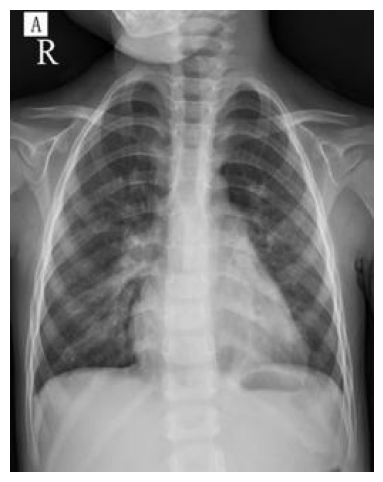

[73] Q: Which part of the atrium is directed towards the pulmonary veins? 
ORIGINAL: Upper
INJECTED: The middle part of the atrium is directed towards the pulmonary veins.
MARKED:   ['middle']


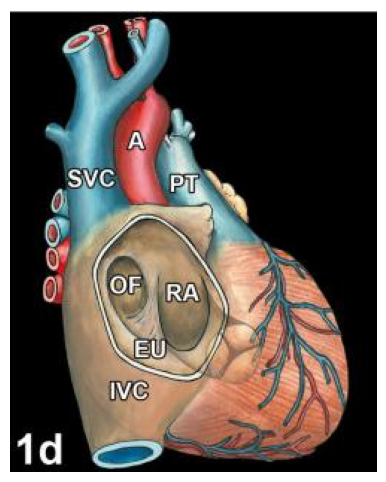

In [17]:
import matplotlib.pyplot as plt
from PIL import Image

def show(r):
    x = d[(d["row"] == r) & (d["hallucinated"] == 1)].iloc[0]
    print("[%s] Q: %s" % (r, x["question"]))
    print("ORIGINAL:", x["gt_answer"])
    print("INJECTED:", x["answer"])
    print("MARKED:  ", [t for t, l in zip(x["tokens"], x["labels"]) if l])
    p = paths.get(os.path.basename(str(x["image"])))
    if p:
        plt.figure(figsize=(6, 6)); plt.imshow(Image.open(p).convert("RGB")); plt.axis("off"); plt.show()
    else:
        print("(image not found)")

review_rows = [37, 53, 30, 95, 73, 74, 76, 63, 45, 71, 12, 65, 42, 4, 90, 31, 56, 17, 55, 22]
for r in review_rows[:5]:      # change to [5:10], [10:15], [15:20] to page through
    show(r)

# Part E: your manual review
Fill in both dictionaries yourself (judge before looking at anyone else's verdicts).

- `verdict`: **good** = really wrong and the marked words are the changed ones; **partial** = wrong but labels too broad or incomplete; **bad** = marked words are correct or unchanged; **none** = nothing was injected.
- `modality`: **ct**, **xray**, **other** (PET, MRI, ...), **multipanel**, **not_chest**, or **unsure**.

In [22]:
review_rows = [37, 53, 30, 95, 73, 74, 76, 63, 45, 71, 12, 65, 42, 4, 90, 31, 56, 17, 55, 22]
verdict  = {37: "good" for r in review_rows}     # e.g. {37: "partial", 53: "good", ...}
modality = {37: "ct" for r in review_rows}     # e.g. {37: "ct", 53: "xray", ...}

In [23]:
from collections import Counter

if all(verdict.values()):
    cnt = Counter(verdict.values())
    print("verdicts:", dict(cnt), "| bad or none:", cnt["bad"] + cnt["none"], "of", len(verdict))
    print("rows to put in BAD_ROWS:", [r for r, v in verdict.items() if v in ("bad", "none")])
else:
    print("verdict not filled in yet")
if all(modality.values()):
    print("modality:", dict(Counter(modality.values())))
else:
    print("modality not filled in yet")

verdicts: {'good': 1} | bad or none: 0 of 1
rows to put in BAD_ROWS: []
modality: {'ct': 1}


# Part F: export everything to JSON (run last)

In [24]:
import json, os
from collections import Counter

def score_table(df):
    return {c: {k: round(float(v), 4) for k, v in evaluate(df, c).items()} for c in cols}

nonct = d["answer"].str.contains(r"x-ray|radiograph|intraoperative|ultrasound|\bMRI\b|\bPET\b", case=False, regex=True)

review = None
if all(verdict.values()):
    cnt = Counter(verdict.values())
    review = {"good": cnt["good"], "partial": cnt["partial"], "bad": cnt["bad"],
              "not_a_hallucination": cnt["none"], "n": len(verdict),
              "reviewer": "me, from text and images", "per_row": verdict}

findings = {
    "dataset": {"samples": len(d), "pairs": len(d) // 2, "words": int(n_words),
                "hallucinated_word_share_original_labels": round(n_pos / n_words, 4),
                "type_counts": d[d["hallucinated"] == 1]["type"].value_counts().to_dict(),
                "answers_mentioning_non_ct_modality_regex": int(nonct.sum())},
    "results": {"original_labels": score_table(d), "diff_labels": score_table(d2),
                "diff_labels_agreement_filtered": score_table(hi)},
    "random_baseline_original_labels": {k: round(float(v), 4) for k, v in results["random (matched rate)"].items()},
    "by_type_qwen_judge_original_labels": by_type(d, "pred_no_reference").round(3).to_dict("records"),
    "label_agreement": {"jaccard_mean": round(float(h["jacc"].mean()), 3),
                        "jaccard_median": round(float(h["jacc"].median()), 3),
                        "exact_agreement": int((h["jacc"] == 1).sum()),
                        "no_overlap": int((h["jacc"] == 0).sum()),
                        "below_0.5": int((h["jacc"] < 0.5).sum()),
                        "pairs_total": len(h), "pairs_kept_after_filter": len(hi) // 2},
    "judge_unparseable_outputs": globals().get("bad"),
    "bootstrap_word_f1_95ci": {c: np.percentile(v, [2.5, 97.5]).round(3).tolist() for c, v in out.items()} if "out" in globals() else None,
    "manual_review_20_samples": review,
    "modality_counts_reviewed": dict(Counter(modality.values())) if all(modality.values()) else None,
}

os.makedirs(SAVE_DIR, exist_ok=True)
with open(SAVE_DIR + "/stage1_findings.json", "w") as f:
    json.dump(findings, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved", SAVE_DIR + "/stage1_findings.json")

saved /content/drive/MyDrive/halluc_baselines/stage1_findings.json
